In [14]:
import pandas as pd
import numpy as np
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score




In [15]:
df = pd.read_csv('empleados.csv', delimiter=";")

In [16]:
print(df.head())

      Nombre       Sexo Estado_Civil  Edad  Experiencia  Salario Gerencia  \
0  Alexandro  Masculino   Soltero(a)    22            3     2423       No   
1     Felipa   Femenino   Soltero(a)    26            5     2639       No   
2     Daniel  Masculino    Casado(a)    35           10     3122       No   
3       John  Masculino    Casado(a)    35           13     3431       Sí   
4    Ruperta   Femenino    Casado(a)    54           18     3962       No   

           Departamento  
0            Publicidad  
1             Comercial  
2             Comercial  
3  Servicios al cliente  
4              Producto  


Dividir df en dos matrices: Una con las características dependientes (Salario) y otra independiente (experiencia)

In [17]:
X = df['Experiencia'].values.reshape(-1,1)
y = df['Salario'].values.reshape(-1,1)

Dividir en set de entrenamiento y test

In [18]:
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2)

Regresión lineal

R² en test: 0.9838 | MAE: 67.4118 | RMSE: 84.7761


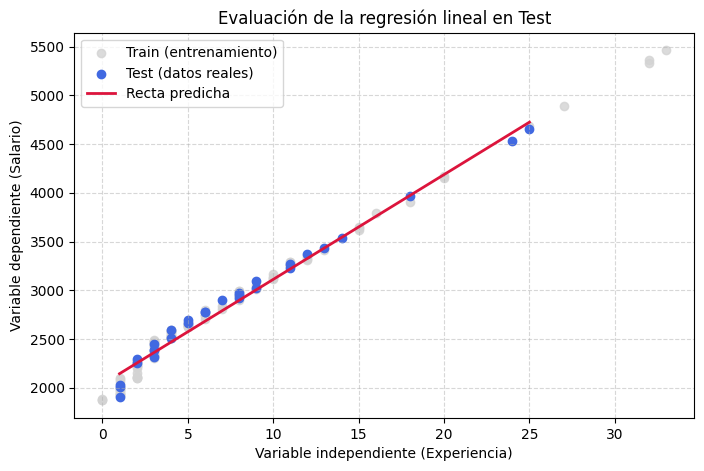

In [20]:

# 1. Entrenar SOLO con train
modelo = LinearRegression()
modelo.fit(X_train, y_train)

# 2. Predecir sobre test (datos nuevos para el modelo)
y_pred = modelo.predict(X_test)

# 3. Calcular métricas de evaluación en test
r2 = r2_score(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))

print(f"R² en test: {r2:.4f} | MAE: {mae:.4f} | RMSE: {rmse:.4f}")

# 4. Representar visualmente train vs test
plt.figure(figsize=(8, 5))
plt.scatter(
    X_train, y_train, color="lightgray", label="Train (entrenamiento)", alpha=0.8
)
plt.scatter(X_test, y_test, color="royalblue", label="Test (datos reales)")

# Ordenar X_test para que la línea se dibuje limpia de izquierda a derecha
orden = np.argsort(X_test.ravel())
plt.plot(
    X_test[orden],
    y_pred[orden],
    color="crimson",
    linewidth=2,
    label="Recta predicha",
)

plt.title("Evaluación de la regresión lineal en Test")
plt.xlabel("Variable independiente (Experiencia)")
plt.ylabel("Variable dependiente (Salario)")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.5)
plt.show()